In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [2]:
L = tf.keras.layers

In [3]:
tr = pd.read_csv("sg/sign_mnist_train.csv")
te = pd.read_csv("sg/sign_mnist_test.csv")
Xtr,ytr = tr.drop(columns="label").values.reshape(-1,28,28,1) / 255, tr.label.values
Xte,yte = te.drop(columns="label").values.reshape(-1,28,28,1) / 255, te.label.values

In [4]:
model = tf.keras.Sequential([L.Flatten(), L.Dense(256, activation="relu"), L.Dense(128, activation="relu"), L.Dense(25, activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=12, batch_size=128, validation_data=(Xte, yte))

Epoch 1/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.2240 - loss: 2.6797 - val_accuracy: 0.4861 - val_loss: 1.7187
Epoch 2/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5913 - loss: 1.3440 - val_accuracy: 0.6035 - val_loss: 1.2866
Epoch 3/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7097 - loss: 0.9370 - val_accuracy: 0.6454 - val_loss: 1.1382
Epoch 4/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7893 - loss: 0.6989 - val_accuracy: 0.7052 - val_loss: 0.9813
Epoch 5/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8375 - loss: 0.5344 - val_accuracy: 0.6934 - val_loss: 0.9653
Epoch 6/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8936 - loss: 0.3788 - val_accuracy: 0.7009 - val_loss: 0.9855
Epoch 7/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9254 - loss: 0.2876 - val_accuracy: 0.7029 - val_loss: 0.9852
Epoch 8/12
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9482 - loss: 0.2108 - val_accuracy: 0.

In [6]:
print(model.evaluate(Xte, yte))                                  
print(classification_report(yte, model.predict(Xte).argmax(1)))  

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7354 - loss: 1.1262
[1.0979222059249878, 0.740379273891449]
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.74      1.00      0.85       331
           1       1.00      0.86      0.92       432
           2       0.96      0.93      0.94       310
           3       0.69      0.91      0.79       245
           4       0.78      0.96      0.86       498
           5       0.67      0.82      0.74       247
           6       0.86      0.79      0.83       348
           7       0.95      0.81      0.87       436
           8       0.55      0.85      0.67       288
          10       0.72      0.54      0.62       331
          11       0.74      0.90      0.81       209
          12       0.92      0.60      0.73       394
          13       0.65      0.51      0.57       291
          14       0.88      0.65      0.75       246
          15       1.00      0.97

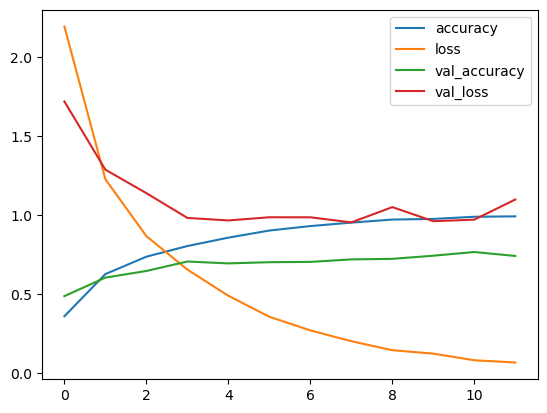

In [7]:
pd.DataFrame(h.history).plot(); 
plt.show()                       

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


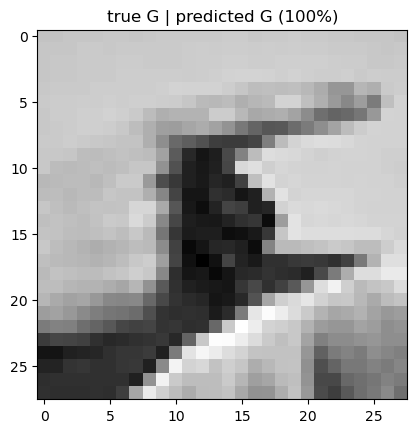

In [8]:
#one example
names = [chr(65+k) for k in range(25)]                         # label 0 = A ... 24 = Y
i = 0                                                          # any test image
p = model.predict(Xte[i:i+1])[0]                               # one probability per class
plt.imshow(Xte[i].squeeze(), cmap="gray"); plt.title(f"true {names[yte[i]]} | predicted {names[p.argmax()]} ({p.max():.0%})")
plt.show()